# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import SARACDDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader
import numpy as np 

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/SAR-ACD/",
    "csv_file": "./data/SAR-ACD/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = SARACDDataset(dataset_config)

## Show images from the dataset

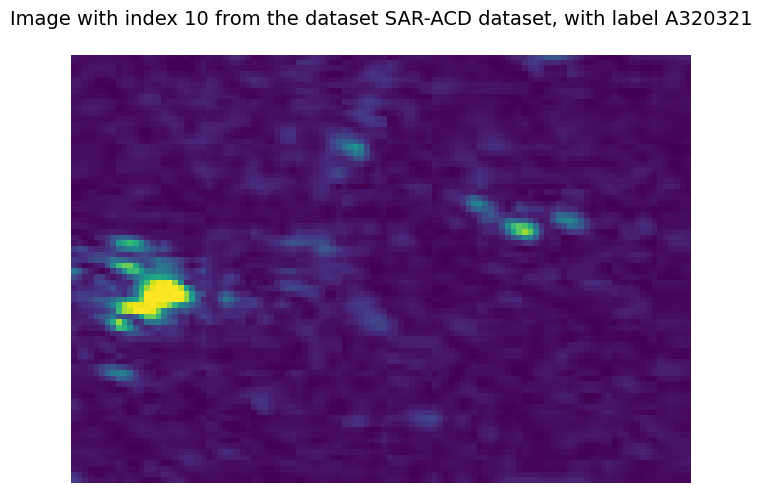

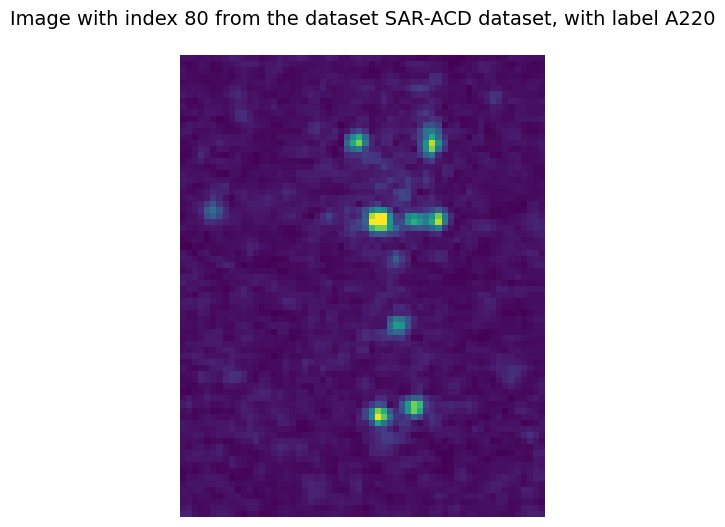

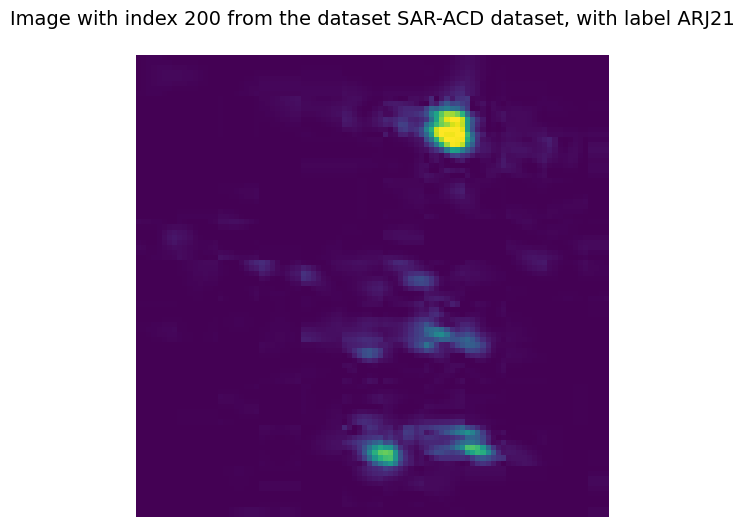

In [18]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

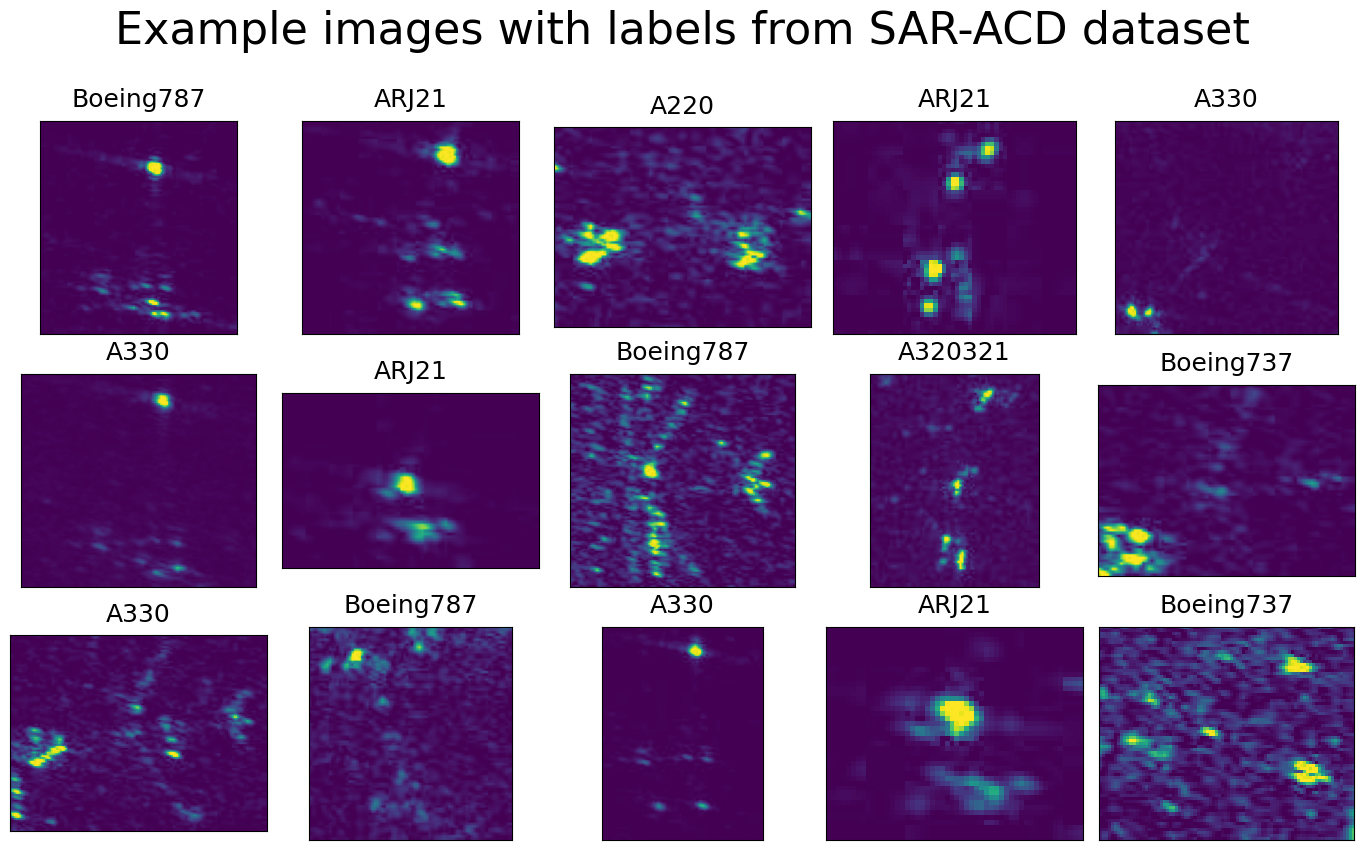

In [8]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [9]:
dataset.show_samples()

,File name,Label
0,A330/204.jpg,A330
1,Boeing737/449.jpg,Boeing737
2,A330/223.jpg,A330
3,Boeing787/478.jpg,Boeing787
4,ARJ21/225.jpg,ARJ21
5,A220/234.jpg,A220
6,A220/309.jpg,A220
7,Boeing737/389.jpg,Boeing737
8,A330/008.jpg,A330
9,A220/096.jpg,A220


In [10]:
dataset.data_distribution_table()

,Label,Count
0,A220,371
1,A320321,397
2,A330,403
3,ARJ21,411
4,Boeing737,429
5,Boeing787,415


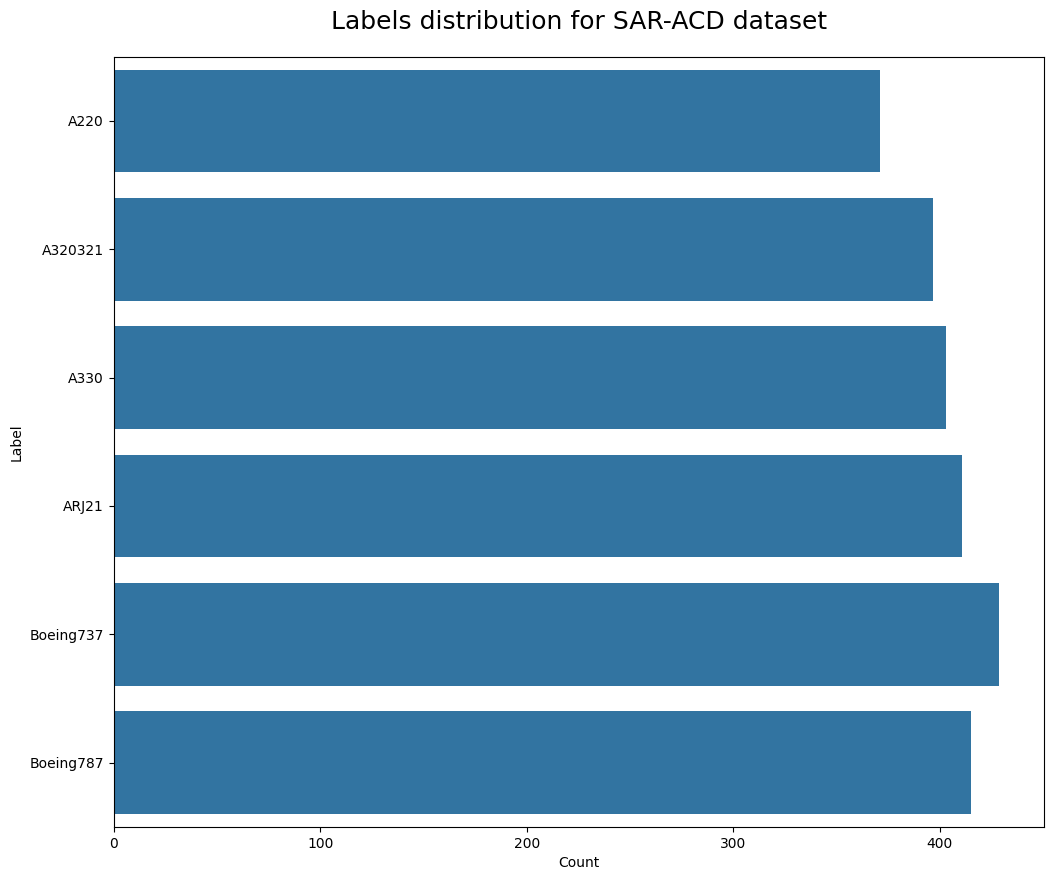

In [11]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/SAR-ACD/",
    "csv_file": "./data/SAR-ACD/train.csv",
}

train_dataset = SARACDDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/SAR-ACD/",
    "csv_file": "./data/SAR-ACD/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = SARACDDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(2426, 303)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/SAR-ACD/"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-21 12:25:32,983 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-21 12:25:33,590 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [8]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-21 12:25:35,745 INFO Starting training.
training: 100%|██████████| 76/76 [01:08<00:00,  1.11it/s]
2025-05-21 12:26:44,857 INFO epoch: 1, time: 68, loss:  1.27967
testing on train set: 100%|██████████| 76/76 [00:25<00:00,  3.02it/s]
2025-05-21 12:27:12,191 INFO Accuracy:0.6319043693322342, Precision Micro:0.6319043693322342, Precision Macro:0.6858877989688413, Precision Weighted:0.6887171642839015, Precision per Class:[0.6416185  0.43100996 0.76415094 0.87878788 0.83154122 0.5682183 ], Recall Micro:0.6319043693322342, Recall Macro:0.627465653259724, Recall Weighted:0.6319043693322342, Recall per Class:[0.29919137 0.76322418 0.60297767 0.70559611 0.54079254 0.85301205], F1_score Micro:0.6319043693322336, F1_score Macro:0.6255392214764081, F1_score Weighted:0.6297097637852532, F1_score per Class:[0.40808824 0.55090909 0.6740638  0.78272605 0.65536723 0.68208092]
testing on validation set: 100%|██████████| 10/10 [00:03<00:00,  2.85it/s]
2025-05-21 12:27:15,715 INFO Accuracy:0.64026

0.2861625367909154

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/SAR-ACD/",
    "csv_file": "./data/SAR-ACD/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = SARACDDataset(test_dataset_config)
model_path = "./data/experiments/SAR-ACD/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-21 12:50:06,802 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SAR-ACD/checkpoint.pth.tar
2025-05-21 12:50:07,612 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SAR-ACD/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 19/19 [00:02<00:00,  6.79it/s]


[{'Accuracy': 0.8679867986798679},
 {'Precision Micro': 0.8679867986798679,
  'Precision Macro': 0.8614276154939785,
  'Precision Weighted': 0.866754153519551,
  'Precision per Class': array([0.7       , 0.76923077, 0.94339623, 0.93103448, 0.9137931 ,
         0.91111111])},
 {'Recall Micro': 0.8679867986798679,
  'Recall Macro': 0.8643748922570977,
  'Recall Weighted': 0.8679867986798679,
  'Recall per Class': array([0.77777778, 0.6122449 , 0.92592593, 0.96428571, 0.92982456,
         0.97619048])},
 {'F1_score Micro': 0.8679867986798674,
  'F1_score Macro': 0.8608126689088783,
  'F1_score Weighted': 0.8653869448047546,
  'F1_score per Class': array([0.73684211, 0.68181818, 0.93457944, 0.94736842, 0.92173913,
         0.94252874])}]

## Predictions

2025-05-21 12:50:14,593 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SAR-ACD/checkpoint.pth.tar
2025-05-21 12:50:15,387 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SAR-ACD/checkpoint.pth.tar at epoch 11


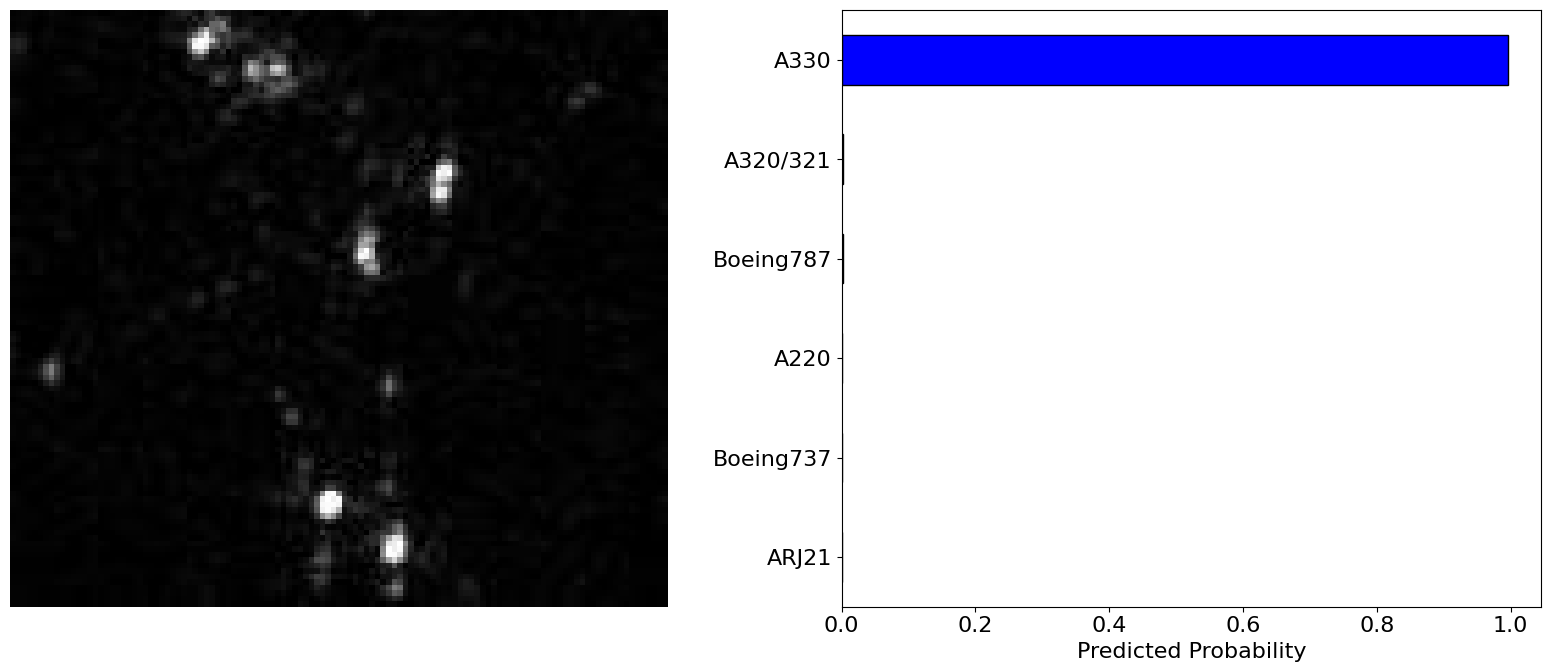

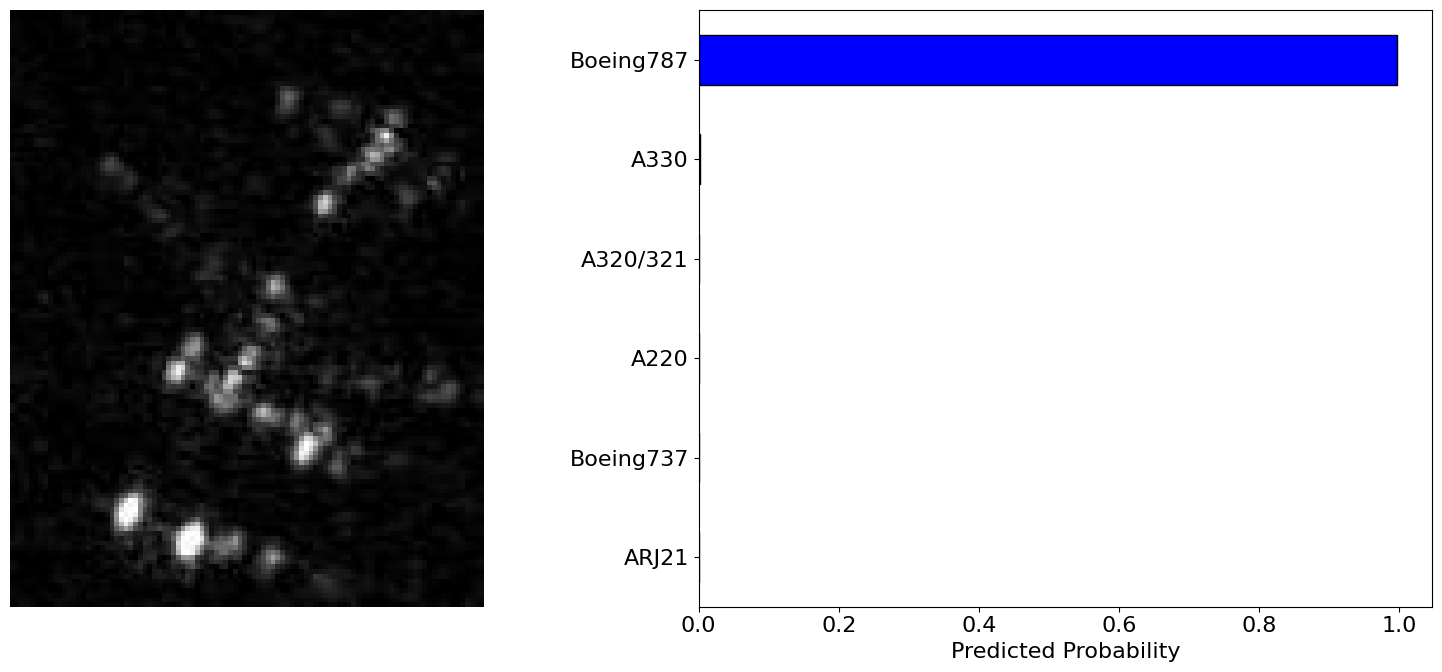

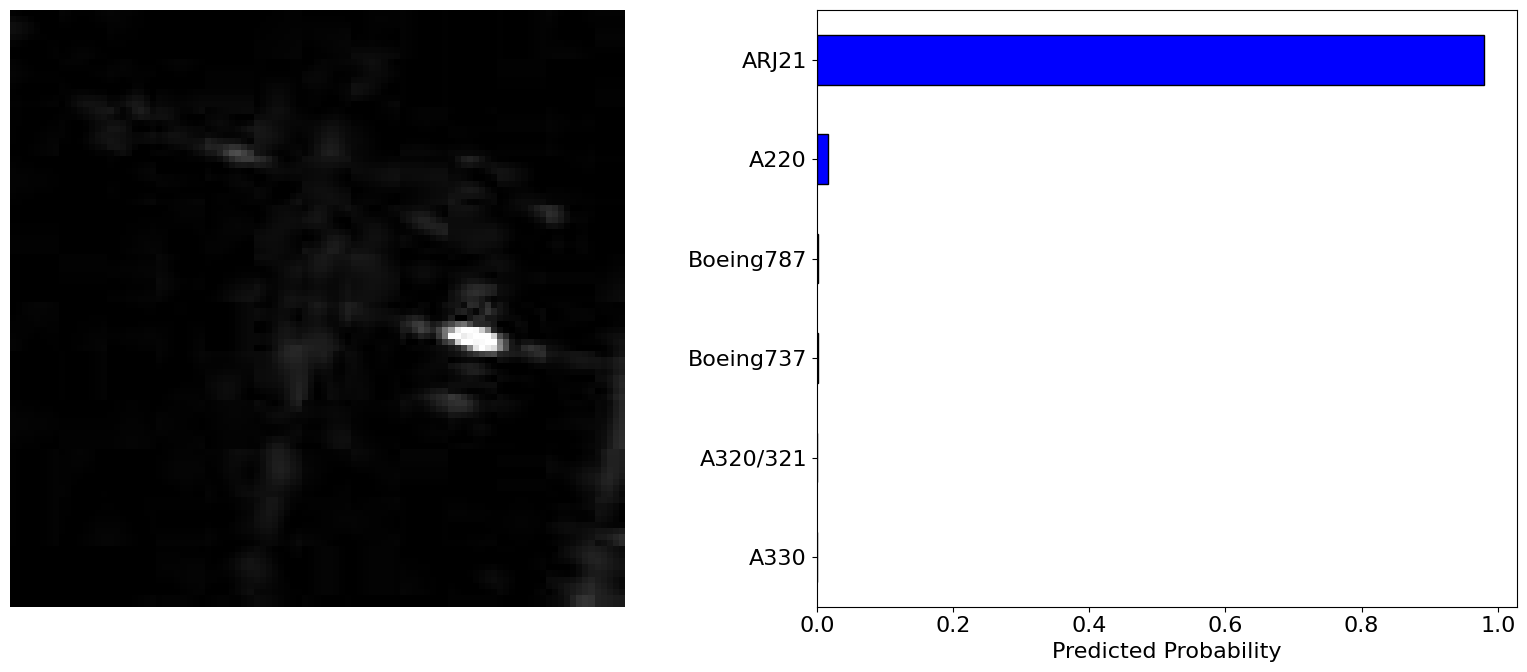

In [ ]:
labels = ["A220","A320/321","A330","ARJ21","Boeing737","Boeing787"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/SAR-ACD/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/SAR-ACD/A330/439.jpg')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/SAR-ACD/Boeing787/230.jpg')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/SAR-ACD/ARJ21/080.jpg')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)